---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 3"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 12. Генератори гармонійних коливань</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>3.9. Генератори електричних коливань: основні поняття і визначення; баланс фаз і баланс амплітуд; класифікація генераторів</li>
  <li>3.10. Генератори гармонічних коливань з LC-контуром: принцип дії, переваги та недоліки, розрахункові співвідношення, приклад схеми</li>
  <li>3.11. RC-генератор на операційному підсилювачі: принцип дії, розрахункові співвідношення, переваги та недоліки, приклад схеми</li>
  <li>3.12. Стабілізація частоти генераторів</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 12 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Генератори: основні поняття, умови самозбудження, класифікація](#gen-basics)
* [LC-генератори гармонічних коливань](#lc-gen)
    * [🔬 Інтерактивно: генератор Колпітца: запуск коливань і баланс амплітуд (PySpice)](#colpitts-interactive)
* [RC-генератор на ОП з мостом Віна](#wien)
    * [🔬 Інтерактивно: генератор Віна на μA741: запуск, амплітуда, спектр (PySpice)](#wien-interactive)
* [Стабілізація частоти генераторів](#freq-stab)
    * [🔬 Інтерактивно: імпеданс кварцового резонатора](#crystal-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Генератори: основні поняття, умови самозбудження, класифікація <a class="anchor" id="gen-basics"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.9</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Давати визначення автогенератора і пояснювати механізм виникнення коливань
> - Формулювати умови балансу фаз і балансу амплітуд
> - Класифікувати генератори за формою коливань, частотозадавальним колом, режимом роботи

</div>

**Електронний генератор** — пристрій, що перетворює енергію джерела живлення в енергію незатухаючих електричних коливань заданої форми і частоти. **Автогенератор** працює в режимі самозбудження — коливання виникають самі після ввімкнення живлення, без зовнішнього сигналу. На відміну від нього, **генератор із зовнішнім запуском** (чекальний) формує сигнал лише після керувального імпульсу (одновібратори, тема 14).

### Умови самозбудження

Генератор — це підсилювач $K(j\omega)$, охоплений **позитивним** ЗЗ через коло $\beta(j\omega)$. З основного рівняння ЗЗ (тема 2)
$$K_{зз} = \frac{K}{1 - \beta K} \to \infty\quad\text{при}\quad \beta(j\omega_0)K(j\omega_0) = 1:$$
скінченний вихідний сигнал існує за нульового вхідного. Комплексна рівність розпадається на дві:
- **баланс фаз:** $\;\varphi_K(\omega_0) + \varphi_\beta(\omega_0) = 2\pi n,\;n = 0, 1, \ldots$ — сигнал, обійшовши петлю, повертається у фазі з самим собою; ця умова **визначає частоту генерації**;
- **баланс амплітуд:** $\;|K(\omega_0)|\cdot|\beta(\omega_0)| = 1$ — втрати в петлі точно компенсуються підсиленням; ця умова **визначає амплітуду**.

Для **запуску** коливань потрібно $|\beta K| > 1$ (зазвичай 1,1…1,5): малі флуктуації (шум, ввімкнення живлення) на частоті $\omega_0$ наростають експоненційно. Наростання припиняється, коли через нелінійність (обмеження підсилювача, нелінійний елемент у колі ЗЗ, АРП) середнє петльове підсилення зменшується до 1 — встановлюється **стаціонарна амплітуда**. Чим ближче $|\beta K|$ до 1 у стаціонарному режимі і чим «м'якше» обмеження, тим менші нелінійні спотворення.

Для **гармонічних** коливань баланс фаз має виконуватися лише на одній частоті — у петлі потрібне **виборче коло** з крутою ФЧХ (LC-контур, кварц, міст Віна). Для **релаксаційних** (прямокутних, трикутних) генераторів умова виконується в широкій смузі.

### Класифікація

| Ознака | Види |
|---|---|
| Форма коливань | гармонічних (синусоїдних); релаксаційні (прямокутних, трикутних, пилкоподібних імпульсів) — мультивібратори |
| Частотозадавальне коло | LC; RC; кварцові (п'єзоелектричні); на лініях передачі, об'ємних резонаторах, ПАХ |
| Діапазон частот | інфранизькочастотні (< 10 Гц), низькочастотні (до 100 кГц), високочастотні, НВЧ |
| Режим роботи | автогенератори; з зовнішнім збудженням (чекальні); керовані напругою (ГКН/VCO) |
| Активний елемент | на транзисторах, ОП, логічних елементах, таймерах, на приладах з від'ємним опором (тунельний діод, діод Ганна) |

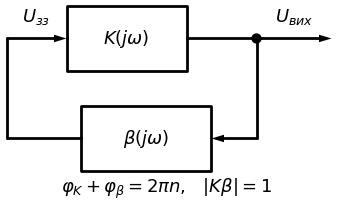

In [2]:
# Структурна схема автогенератора: підсилювач K і коло позитивного ЗЗ β
if SCHEMDRAW_AVAILABLE:
    import schemdraw.dsp as dsp
    with schemdraw.Drawing(fontsize=13, unit=1.5) as d:
        d += (k := dsp.Box(w=2.4, h=1.3).label('$K(j\\omega)$').at((0, 0)).anchor('W'))
        d += dsp.Line().at(k.E).right(1.4)
        d += (n := elm.Dot())
        d += dsp.Arrow().right(1.5).label('$U_{вих}$', loc='top')
        d += dsp.Line().at(n.center).down(2.0)
        d += dsp.Arrow().left(0.9)
        d += (b := dsp.Box(w=2.6, h=1.3).label('$\\beta(j\\omega)$').anchor('E'))
        d += dsp.Line().at(b.W).left().tox(-1.2)
        d += dsp.Line().up().toy(k.W)
        d += dsp.Arrow().right().tox(k.W).label('$U_{зз}$', loc='top')
        d += elm.Label().at((1.9, -3.1)).label('$\\varphi_K + \\varphi_\\beta = 2\\pi n$,   $|K\\beta| = 1$', fontsize=13)

---

## LC-генератори гармонічних коливань <a class="anchor" id="lc-gen"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.10</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати принцип дії LC-генератора з трансформаторним зв'язком і трьохточкових схем
> - Показувати, якими елементами забезпечуються баланс фаз і баланс амплітуд
> - Розраховувати частоту генерації і умову самозбудження ємнісної трьохточки (Колпітца)

</div>

Частотозадавальне коло LC-генератора — **паралельний коливальний контур**; на резонансній частоті
$$f_0 = \frac{1}{2\pi\sqrt{LC}}$$
його опір чисто активний і максимальний ($R_{рез} = Q\rho$, $\rho = \sqrt{L/C}$), тож каскад із контуром у навантаженні має максимальне підсилення і фазовий зсув рівно $180°$ (СЕ) або $0°$ (СБ). Енергія в контурі коливається між $L$ і $C$, а активний елемент лише поповнює втрати.

### Схеми
1. **З трансформаторним (індуктивним) зв'язком (Мейсснера).** Контур $LC$ — у колі колектора, котушка зв'язку $L_{зв}$ подає частину напруги на базу. **Баланс фаз**: каскад СЕ дає $180°$, а ще $180°$ — правильне ввімкнення кінців котушки зв'язку (зустрічне). **Баланс амплітуд**: коефіцієнт трансформації $n = M/L$ вибирають з умови $n\cdot K \ge 1$.
2. **Індуктивна трьохточка (Хартлі).** Котушка контуру має відвід, з'єднаний з емітером; напруги на частинах котушки протифазні відносно відводу.
3. **Ємнісна трьохточка (Колпітца).** Ємність контуру складена з двох послідовних конденсаторів $C_1$, $C_2$, точка їх з'єднання — до емітера:
$$f_0 = \frac{1}{2\pi\sqrt{L\,C_e}},\qquad C_e = \frac{C_1C_2}{C_1 + C_2},\qquad \beta = \frac{C_1}{C_1 + C_2}\;(\text{схема зі спільною базою}).$$
**Баланс фаз** забезпечує ємнісний подільник (каскад СБ не інвертує, подільник передає частину напруги контуру в емітер у фазі). **Баланс амплітуд**: $g_m\,R_{рез}\,\beta \ge 1$; його досягають вибором струму транзистора (крутизни) і відношення $C_2/C_1$. Стаціонарна амплітуда встановлюється за рахунок нелінійності транзистора (обмеження, автозміщення через $R_е$, $C_б$).

Правило трьохточок: для генерації опори «емітер–база» і «емітер–колектор» мають бути **однакового** характеру (обидва ємнісні або обидва індуктивні), а «база–колектор» — протилежного.

**Переваги LC-генераторів:** висока частота (від сотень кілогерц до гігагерц), добра форма синуса (контур фільтрує гармоніки), велика потужність. **Недоліки:** на низьких частотах потрібні громіздкі котушки; стабільність частоти обмежена добротністю контуру і температурною залежністю $L$, $C$ ($10^{-3}\ldots10^{-4}$).

**Застосування:** гетеродини радіоприймачів, задавальні генератори передавачів, ГКН у синтезаторах частоти (з варикапом у контурі), індукційний нагрів, металошукачі.

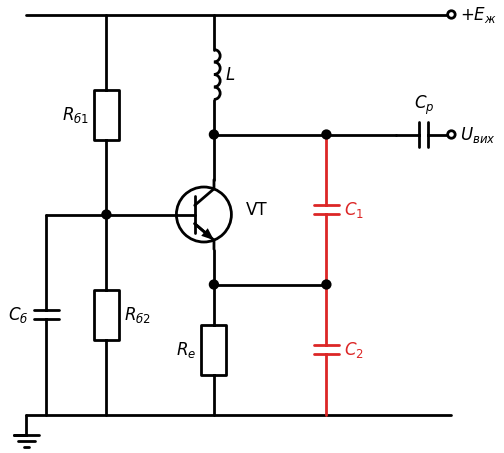

In [3]:
# Ємнісна трьохточка (схема Колпітца) на транзисторі зі спільною базою
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 8), (8.5, 8)); d += elm.Dot(open=True).at((8.5, 8)).label('$+E_ж$', loc='right')
        d += W((0, 0), (8.5, 0)); d += elm.Ground().at((0, 0))
        d += elm.BjtNpn(circle=True).theta(0).at((3.0, 4.0)).anchor('base'); d += elm.Label().at((4.5, 4.0)).label('VT')
        d += elm.Resistor().at((1.6, 8)).to((1.6, 4.0)).label('$R_{б1}$', loc='top'); d += W((1.6, 4.0), (3.0, 4.0)); d += elm.Dot().at((1.6, 4.0))
        d += elm.Resistor().at((1.6, 4.0)).to((1.6, 0)).label('$R_{б2}$', loc='bottom')
        d += W((1.6, 4.0), (0.4, 4.0)); d += elm.Capacitor().at((0.4, 4.0)).to((0.4, 0)).label('$C_б$', loc='top')
        d += elm.Inductor().at((3.75, 8)).to((3.75, 5.6)).label('$L$', loc='bottom'); d += W((3.75, 5.6), (3.75, 4.7)); d += elm.Dot().at((3.75, 5.6))
        d += W((3.75, 3.3), (3.75, 2.6)); d += elm.Dot().at((3.75, 2.6))
        d += elm.Resistor().at((3.75, 2.6)).to((3.75, 0)).label('$R_е$', loc='top')
        d += W((3.75, 5.6), (6.0, 5.6)); d += elm.Capacitor().at((6.0, 5.6)).to((6.0, 2.6)).label('$C_1$', loc='bottom').color('#dc2626')
        d += elm.Dot().at((6.0, 2.6)); d += W((3.75, 2.6), (6.0, 2.6))
        d += elm.Capacitor().at((6.0, 2.6)).to((6.0, 0)).label('$C_2$', loc='bottom').color('#dc2626')
        d += elm.Dot().at((6.0, 5.6)); d += W((6.0, 5.6), (7.4, 5.6)); d += elm.Capacitor().at((7.4, 5.6)).to((8.5, 5.6)).label('$C_р$')
        d += elm.Dot(open=True).at((8.5, 5.6)).label('$U_{вих}$', loc='right')

---
### 🔬 Інтерактивно: генератор Колпітца: запуск коливань і баланс амплітуд (PySpice) <a class="anchor" id="colpitts-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Генератор на 2N3904 ($L = 100$ мкГн, $E_ж = 12$ В) — схема вище. Змінюйте $C_2$ (при $C_1 = 1$ нФ): змінюються і частота, і коефіцієнт ЗЗ $\beta = C_1/(C_1 + C_2)$. Збільшуйте $R_е$ — струм і крутизна транзистора зменшуються; коли $g_mR_{рез}\beta < 1$, генерація зриває. Праворуч — спектр стаціонарних коливань.

</div>

In [4]:
# Генератор Колпітца на 2N3904: перехідний процес і спектр
def colpitts(C2_nF=3.3, Re_k=1.0):
    L, C1 = 100e-6, 1e-9
    c = Circuit('Colpitts')
    c.include(spice_model('2n3904.lib'))
    c.V('cc', 'vcc', c.gnd, 12)
    c.R('b1', 'vcc', 'b', 47e3); c.R('b2', 'b', c.gnd, 10e3); c.C('b', 'b', c.gnd, 100e-9)
    c.L(1, 'vcc', 'c', L); c.BJT(1, 'c', 'b', 'e', model='Q2N3904'); c.R('e', 'e', c.gnd, Re_k * 1e3)
    c.C(1, 'c', 'e', C1); c.C(2, 'e', c.gnd, C2_nF * 1e-9)
    t, v = tran(c, 10e-9, 300e-6)
    u = v['c'] - 12
    Ce = C1 * C2_nF * 1e-9 / (C1 + C2_nF * 1e-9); f0 = 1 / (2 * np.pi * np.sqrt(L * Ce))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
    a1.plot(t * 1e6, u, color='#F44336', lw=1); a1.set_xlabel('t, мкс'); a1.set_ylabel('$u_к - E_ж$, В')
    m = t > 200e-6
    if np.ptp(u[m]) > 0.5:
        tt = np.linspace(t[m][0], t[m][-1], 2 ** 14); uu = np.interp(tt, t, u)
        S = np.abs(np.fft.rfft((uu - uu.mean()) * np.hanning(len(uu)))); fr = np.fft.rfftfreq(len(uu), tt[1] - tt[0])
        a2.plot(fr / 1e6, 20 * np.log10(S / S.max() + 1e-9), color='#2196F3'); a2.set_xlim(0, 4 * f0 / 1e6); a2.set_ylim(-80, 5)
        fg = fr[np.argmax(S)]
        a1.set_title(f'Генерація: f = {fg/1e3:.0f} кГц (теорія {f0/1e3:.0f} кГц), розмах {np.ptp(u[m]):.1f} В')
    else:
        a1.set_title('Генерація зірвалась: |βK| < 1')
    a2.set_xlabel('f, МГц'); a2.set_ylabel('дБ'); a2.set_title('Спектр')
    plt.tight_layout(); plt.show()
    print(f'β = C1/(C1+C2) = {C1/(C1+C2_nF*1e-9):.3f};  C_e = {Ce*1e12:.0f} пФ')

interact(colpitts,
         C2_nF=widgets.FloatSlider(min=1, max=20, step=0.1, value=3.3, description='C2 (нФ)'),
         Re_k=widgets.FloatSlider(min=0.5, max=20, step=0.5, value=1.0, description='Rе (кОм)'));

interactive(children=(FloatSlider(value=3.3, description='C2 (нФ)', max=20.0, min=1.0), FloatSlider(value=1.0,…

---

## RC-генератор на ОП з мостом Віна <a class="anchor" id="wien"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.11</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати, як міст Віна і неінвертувальний підсилювач забезпечують баланс фаз і амплітуд
> - Розраховувати частоту генерації і коефіцієнт підсилення
> - Пояснювати способи стабілізації амплітуди (діоди, лампа, польовий транзистор)

</div>

RC-генератори використовують на низьких частотах (від долей герца до ~1 МГц), де котушки неприйнятно великі.

### Генератор з мостом Віна

Міст Віна (послідовне $RC$ + паралельне $RC$, тема 10) з'єднує вихід ОП з **неінвертувальним** входом (позитивний ЗЗ). На частоті
$$f_0 = \frac{1}{2\pi RC}$$
його фазовий зсув дорівнює нулю, а коефіцієнт передачі $\beta = 1/3$.
- **Баланс фаз** забезпечує міст Віна ($\varphi_\beta = 0$) разом з неінвертувальним підсилювачем ($\varphi_K = 0$);
- **баланс амплітуд** — коло НЗЗ $R_1$, $R_2$ на інвертувальному вході: $K = 1 + R_2/R_1 = 3$.

Для запуску беруть $K$ трохи більше 3 (3,1…3,3), а **стабілізацію амплітуди** забезпечують нелінійним елементом у колі НЗЗ, що зменшує $K$ до 3 при зростанні амплітуди:
- **зустрічно-паралельні діоди** (або стабілітрони) паралельно частині $R_2$ — просто, але $K_г \sim 1\ldots3\%$;
- **лампа розжарення** замість $R_1$ (опір зростає з нагрівом) — класичний генератор Hewlett–Packard 200A, $K_г < 0{,}01\%$;
- **польовий транзистор як керований резистор** + детектор амплітуди (система АРП) — малі спотворення, точне регулювання.

**Переваги:** простота, легка перебудова частоти (здвоєний змінний резистор $R$ або конденсатор $C$ — до 10 разів), низький рівень спотворень при плавній АРП. **Недоліки:** низька стабільність частоти (визначається $R$, $C$, $\sim10^{-2}\ldots10^{-3}$), повільне встановлення амплітуди, обмеження за частотою смугою ОП.

### Генератор з фазообертальним RC-колом

Інвертувальний підсилювач ($\varphi_K = 180°$) і трьохланковий RC-ланцюжок ($\varphi_\beta = 180°$ на частоті $f = \dfrac{1}{2\pi\sqrt6\,RC}$, послаблення $1/29$): потрібно $|K| \ge 29$. Простий, але погано перебудовується.

**Застосування RC-генераторів:** звукові генератори і генератори сигналів низької частоти, вимірювачі АЧХ і коефіцієнта гармонік, джерела опорних синусоїдних сигналів (вимірювачі імпедансу, LVDT-датчики), генератори для біоімпедансних вимірювань.

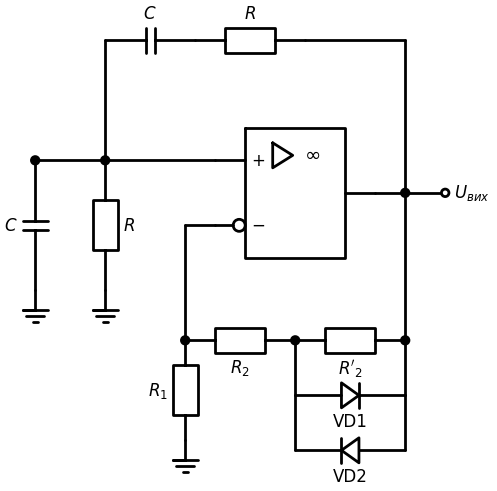

In [5]:
# Генератор з мостом Віна на ОП; діоди VD1, VD2 стабілізують амплітуду
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += (o := OpAmp(swap=True).at((5.0, 2)).anchor('in2'))
        d += W(o.out, (9.6, o.out[1])); d += elm.Dot().at((8.8, o.out[1])); d += elm.Dot(open=True).at((9.6, o.out[1])).label('$U_{вих}$', loc='right')
        # міст Віна: вихід → R → C → вузол (+) → R ∥ C → земля
        d += W((8.8, o.out[1]), (8.8, 4.4)); d += W((8.8, 4.4), (6.8, 4.4))
        d += elm.Resistor().at((6.8, 4.4)).to((4.6, 4.4)).label('$R$'); d += elm.Capacitor().at((4.6, 4.4)).to((2.8, 4.4)).label('$C$')
        d += W((2.8, 4.4), (2.8, 2)); d += W((2.8, 2), (5.0, 2)); d += elm.Dot().at((2.8, 2)); d += elm.Dot().at((1.4, 2))
        d += W((2.8, 2), (1.4, 2))
        d += elm.Resistor().at((2.8, 2)).to((2.8, -0.6)).label('$R$', loc='bottom'); d += elm.Ground().at((2.8, -0.6))
        d += elm.Capacitor().at((1.4, 2)).to((1.4, -0.6)).label('$C$', loc='top'); d += elm.Ground().at((1.4, -0.6))
        # НЗЗ: (−) → R1 → земля; (−) → R2 (з діодами паралельно частині) → вихід
        d += W(o.in1, (4.4, o.in1[1])); d += W((4.4, o.in1[1]), (4.4, -1.6)); d += elm.Dot().at((4.4, -1.6))
        d += elm.Resistor().at((4.4, -1.6)).to((4.4, -3.6)).label('$R_1$', loc='top'); d += elm.Ground().at((4.4, -3.6))
        d += elm.Resistor().at((4.4, -1.6)).to((6.6, -1.6)).label('$R_2$', loc='bottom'); d += elm.Dot().at((6.6, -1.6))
        d += elm.Resistor().at((6.6, -1.6)).to((8.8, -1.6)).label("$R'_2$", loc='bottom'); d += elm.Dot().at((8.8, -1.6))
        d += W((8.8, -1.6), (8.8, o.out[1]))
        d += W((6.6, -1.6), (6.6, -2.7)); d += W((8.8, -1.6), (8.8, -2.7))
        d += elm.Diode().at((6.6, -2.7)).to((8.8, -2.7)).label('VD1', loc='bottom')
        d += W((6.6, -2.7), (6.6, -3.8)); d += W((8.8, -2.7), (8.8, -3.8)); d += elm.Diode().at((8.8, -3.8)).to((6.6, -3.8)).label('VD2', loc='bottom')

---
### 🔬 Інтерактивно: генератор Віна на μA741: запуск, амплітуда, спектр (PySpice) <a class="anchor" id="wien-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Генератор за схемою вище: $R = 10$ кОм, $C = 10$ нФ ($f_0 = 1{,}59$ кГц), $R_1 = 10$ кОм, $R'_2 = 4{,}7$ кОм з діодами. Змінюйте $R_2$: коефіцієнт підсилення при малому сигналі $K = 1 + (R_2 + R'_2)/R_1$. При $K < 3$ генерація не запускається; трохи більше 3 — повільне наростання і мала амплітуда з малими спотвореннями; значно більше 3 — швидкий запуск, але більші амплітуда і коефіцієнт гармонік.

</div>

In [6]:
# Генератор Віна на μA741 зі стабілізацією амплітуди діодами: перехідний процес і коефіцієнт гармонік
def wien(R2_k=17.0, C_nF=10.0):
    R, C = 10e3, C_nF * 1e-9
    c = opamp_circuit('Wien')
    c.model('D', 'D', IS=2.5e-9, N=1.75)
    c.R(1, 'out', 'a', R); c.C(1, 'a', 'p', C); c.R(2, 'p', c.gnd, R); c.C(2, 'p', c.gnd, C)
    c.R('g', 'm', c.gnd, 10e3); c.R('f', 'm', 'x', R2_k * 1e3); c.R('fd', 'x', 'out', 4.7e3)
    c.D(1, 'x', 'out', model='D'); c.D(2, 'out', 'x', model='D')
    c.PulseCurrentSource('kick', c.gnd, 'p', initial_value=0@u_uA, pulsed_value=10@u_uA, pulse_width=20e-6, period=10)   # «поштовх» для запуску
    add_opamp(c, 1, 'p', 'm', 'out')
    f0 = 1 / (2 * np.pi * R * C); T = 1 / f0
    t, v = tran(c, T / 200, 100 * T)
    u = v['out']
    K = 1 + (R2_k + 4.7) / 10
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
    a1.plot(t * 1e3, u, color='#F44336', lw=1); a1.set_xlabel('t, мс'); a1.set_ylabel('$u_{вих}$, В')
    m = t > 70 * T
    if np.ptp(u[m]) > 0.1:
        tt = np.linspace(t[m][0], t[m][-1], 2 ** 14); uu = np.interp(tt, t, u)
        S = np.abs(np.fft.rfft((uu - uu.mean()) * np.hanning(len(uu)))); fr = np.fft.rfftfreq(len(uu), tt[1] - tt[0])
        k1 = np.argmax(S); harm = [S[np.argmin(abs(fr - n * fr[k1]))] for n in range(1, 8)]
        thd = np.sqrt(np.sum(np.square(harm[1:]))) / harm[0] * 100
        a2.plot(fr / 1e3, 20 * np.log10(S / S.max() + 1e-9), color='#2196F3'); a2.set_xlim(0, 8 * f0 / 1e3); a2.set_ylim(-90, 5)
        a1.set_title(f'K = {K:.2f}: f = {fr[k1]:.0f} Гц (теорія {f0:.0f}), амплітуда {np.ptp(u[m])/2:.2f} В, Kг = {thd:.2f} %')
    else:
        a1.set_title(f'K = {K:.2f} < 3: генерація не виникає')
    a2.set_xlabel('f, кГц'); a2.set_ylabel('дБ'); a2.set_title('Спектр')
    plt.tight_layout(); plt.show()

interact(wien,
         R2_k=widgets.FloatSlider(min=10, max=30, step=0.5, value=17, description='R2 (кОм)'),
         C_nF=widgets.FloatSlider(min=2, max=50, step=1, value=10, description='C (нФ)'));

interactive(children=(FloatSlider(value=17.0, description='R2 (кОм)', max=30.0, min=10.0, step=0.5), FloatSlid…

---

## Стабілізація частоти генераторів <a class="anchor" id="freq-stab"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 3.12</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Називати чинники нестабільності частоти генераторів
> - Пояснювати параметричні методи стабілізації
> - Пояснювати роботу кварцового резонатора і кварцового генератора, знати методи АПЧ

</div>

**Відносна нестабільність частоти** $\delta f = \Delta f/f_0$ — головний параметр генератора. Типові значення: RC-генератор — $10^{-2}\ldots10^{-3}$; LC — $10^{-3}\ldots10^{-4}$; кварцовий — $10^{-5}\ldots10^{-6}$; термостатований кварцовий — $10^{-8}\ldots10^{-10}$; атомні стандарти — $10^{-11}\ldots10^{-15}$.

**Причини нестабільності:** зміна температури (ТКЄ конденсаторів, ТКІ котушок, параметри транзисторів), зміна напруги живлення і режиму, вплив навантаження, старіння елементів, вологість, вібрації.

### Параметричні методи
- **елементи з малими ТКЄ/ТКІ** і **термокомпенсація** (конденсатори з протилежними ТКЄ);
- **стабілізація живлення** і режиму активного елемента;
- **буферний каскад** (повторювач) між генератором і навантаженням — розв'язка від змін навантаження;
- **слабкий зв'язок** активного елемента з контуром (частковий відвід) і **висока добротність контуру**: частота визначається ФЧХ контуру, і чим крутіша ФЧХ (більша $Q$), тим менше зміщення частоти при зміні фазового зсуву підсилювача: $\delta f \approx \dfrac{\Delta\varphi}{2Q}$;
- **термостатування** всього генератора.

### Кварцова стабілізація

**Кварцовий резонатор** — пластина кварцу з електродами; через п'єзоефект механічні коливання пластини пов'язані з електричними. Еквівалентна схема — послідовний контур $L_к$, $C_к$, $r_к$ (параметри механічного резонансу) паралельно зі статичною ємністю $C_0$ електродів:
$$f_п = \frac{1}{2\pi\sqrt{L_кC_к}}\;(\text{послідовний резонанс}),\qquad f_{пар} = f_п\sqrt{1 + \frac{C_к}{C_0}} \approx f_п\left(1 + \frac{C_к}{2C_0}\right).$$
Особливості: величезна добротність $Q = 10^4\ldots10^6$, дуже малий ТКЧ (зріз AT — $\pm10^{-5}$ у діапазоні −40…+85 °C), відношення $C_к/C_0 \sim 10^{-3}$ — частоти $f_п$ і $f_{пар}$ відрізняються лише на десяті частки відсотка. Між ними кварц має **індуктивний** характер — в трьохточкових схемах він заміняє котушку (схема Пірса — у більшості тактових генераторів мікроконтролерів, на інверторі КМОН з двома конденсаторами).

### Автоматичне підстроювання частоти
- **АПЧ** — частотний детектор порівнює частоту з еталонною і коригує генератор через варикап;
- **ФАПЧ (PLL)** — фазовий детектор порівнює фазу генератора, керованого напругою (ГКН), з фазою еталонного кварцового генератора; разом з дільниками частоти утворює **синтезатор частот** з кварцовою стабільністю на будь-якій частоті сітки.

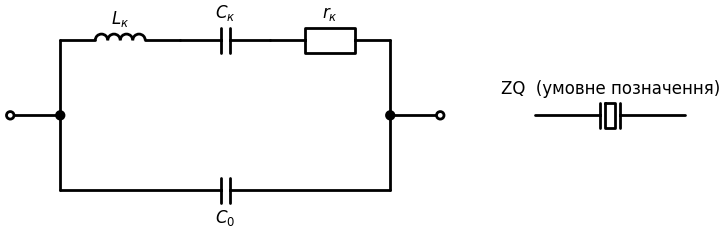

In [7]:
# Еквівалентна схема кварцового резонатора
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Dot(open=True).at((0, 1.5)); d += W((0, 1.5), (1.0, 1.5)); d += elm.Dot().at((1.0, 1.5))
        d += W((1.0, 1.5), (1.0, 3.0)); d += elm.Inductor().at((1.0, 3.0)).to((3.4, 3.0)).label('$L_к$')
        d += elm.Capacitor().at((3.4, 3.0)).to((5.2, 3.0)).label('$C_к$'); d += elm.Resistor().at((5.2, 3.0)).to((7.6, 3.0)).label('$r_к$')
        d += W((7.6, 3.0), (7.6, 1.5)); d += elm.Dot().at((7.6, 1.5))
        d += W((1.0, 1.5), (1.0, 0)); d += elm.Capacitor().at((1.0, 0)).to((7.6, 0)).label('$C_0$', loc='bottom'); d += W((7.6, 0), (7.6, 1.5))
        d += W((7.6, 1.5), (8.6, 1.5)); d += elm.Dot(open=True).at((8.6, 1.5))
        d += elm.Crystal().at((10.5, 1.5)).to((13.5, 1.5)).label('ZQ  (умовне позначення)')

---
### 🔬 Інтерактивно: імпеданс кварцового резонатора <a class="anchor" id="crystal-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Кварц 4 МГц ($L_к = 0{,}1$ Гн, $r_к = 20$ Ом, $C_0 = 5$ пФ, $C_к$ з умови $f_п = 4$ МГц). Між послідовним $f_п$ і паралельним $f_{пар}$ резонансами реактанс додатний (індуктивний) — тут працює кварц у схемі Пірса. Праворуч — порівняння крутизни ФЧХ кварцу і LC-контуру з $Q = 100$: чим крутіша ФЧХ, тим менше зміщується частота генерації при тому самому фазовому збуренні.

</div>

In [8]:
# Імпеданс кварцового резонатора і крутизна ФЧХ у порівнянні з LC-контуром
def crystal(C0_pF=5.0, r_k=20.0):
    fs = 4e6; Lk = 0.1; Ck = 1 / ((2 * np.pi * fs) ** 2 * Lk); C0 = C0_pF * 1e-12
    fp = fs * np.sqrt(1 + Ck / C0)
    f = np.linspace(fs - 2e3, fp + 4e3, 20000); w = 2 * np.pi * f
    Zs = r_k + 1j * w * Lk + 1 / (1j * w * Ck); Z = Zs / (1 + 1j * w * C0 * Zs)
    Q = w[0] * Lk / r_k
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.semilogy((f - fs) / 1e3, np.abs(Z), color='#2196F3', label='|Z|')
    a1.axvline(0, color='#4CAF50', ls=':', label=f'$f_п$ = {fs/1e6:.3f} МГц'); a1.axvline((fp - fs) / 1e3, color='#F44336', ls=':', label=f'$f_{{пар}}$ (+{(fp-fs)/1e3:.2f} кГц)')
    ind = np.imag(Z) > 0
    a1.fill_between((f - fs) / 1e3, 1, 1e8, where=ind, color='#FF9800', alpha=0.15, label='індуктивний характер')
    a1.set_ylim(1, 1e8); a1.set_xlabel('$f - f_п$, кГц'); a1.set_ylabel('|Z|, Ом'); a1.legend(fontsize=9); a1.set_title(f'Кварц: Q = {Q:.0f}, $C_к$ = {Ck*1e15:.1f} фФ')
    x = np.linspace(-0.002, 0.002, 2000)                      # відносне розлаштування
    a2.plot(x * 1e6, np.degrees(-np.arctan(2 * Q * x)), color='#2196F3', label=f'кварц (Q = {Q:.0f})')
    a2.plot(x * 1e6, np.degrees(-np.arctan(2 * 100 * x)), color='#F44336', label='LC-контур (Q = 100)')
    a2.set_xlabel('$\\Delta f/f_0$, ppm'); a2.set_ylabel('φ, град'); a2.legend(fontsize=9); a2.set_title('ФЧХ резонатора (послідовний резонанс)')
    plt.tight_layout(); plt.show()
    print(f'Зміщення частоти при фазовому збуренні 10°: кварц — {np.tan(np.radians(10))/(2*Q)*1e6:.3f} ppm, LC (Q=100) — {np.tan(np.radians(10))/200*1e6:.0f} ppm')

interact(crystal,
         C0_pF=widgets.FloatSlider(min=2, max=20, step=0.5, value=5, description='C0 (пФ)'),
         r_k=widgets.FloatSlider(min=5, max=200, step=5, value=20, description='r_к (Ом)'));

interactive(children=(FloatSlider(value=5.0, description='C0 (пФ)', max=20.0, min=2.0, step=0.5), FloatSlider(…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Умова $|\beta K| = 1$ — для стаціонарного режиму, а не для запуску.** Якщо зробити точно $K = 3$ у генераторі Віна, коливання не запустяться (або згаснуть від найменшого розкиду). Потрібне $|\beta K| > 1$ при малій амплітуді і механізм, що зменшує підсилення до 1 при зростанні амплітуди. Без такого механізму амплітуду обмежує насичення ОП — синусоїда «обрізається», і коефіцієнт гармонік зростає до кількох відсотків.

</div>

---
### ⚡ Практичне застосування: генератори гармонічних коливань

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Застосування | Тип генератора | Стабільність |
|---|---|---|
| Звуковий генератор, вимірювач АЧХ | RC (Віна) з АРП | $10^{-2}$ |
| Гетеродин FM-приймача, ГКН синтезатора | LC з варикапом у ФАПЧ | визначається опорним кварцом |
| Тактовий генератор мікроконтролера | кварцовий (Пірса) на КМОН-інверторі | $10^{-5}$ |
| Годинниковий кварц 32 768 Гц | кварцовий камертонний | $2\cdot10^{-5}$ |
| Базова станція, GPS-приймач | термокомпенсований (TCXO) / термостатований (OCXO) кварц | $10^{-7}\ldots10^{-9}$ |
| Металошукач, індукційний нагрів | LC (Колпітца, Хартлі) | $10^{-3}$ |

</div>

---
### ✅ Питання для самоперевірки: генератори

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Сформулюйте умови самозбудження генератора.</summary>

> **Відповідь:** Баланс фаз: $\varphi_K + \varphi_\beta = 2\pi n$ (визначає частоту); баланс амплітуд: $|K\beta| = 1$ у стаціонарному режимі і $|K\beta| > 1$ для запуску.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> За рахунок яких елементів у генераторі Колпітца забезпечуються баланс фаз і амплітуд?</summary>

> **Відповідь:** Фаз — ємнісним подільником $C_1C_2$ і контуром (неінвертувальний каскад СБ); амплітуд — відношенням $C_1/(C_1+C_2)$, крутизною транзистора (струмом через $R_е$) і нелінійністю транзистора.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому в генераторі Віна $K = 3$?</summary>

> **Відповідь:** Міст Віна на $f_0$ має $\beta = 1/3$ і нульовий фазовий зсув; для $|K\beta| = 1$ потрібно $K = 3$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Навіщо в генераторі Віна діоди або лампа?</summary>

> **Відповідь:** Для стабілізації амплітуди: при зростанні амплітуди вони зменшують підсилення до 3, не допускаючи насичення ОП.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому кварцові генератори стабільні?</summary>

> **Відповідь:** Дуже висока добротність (крута ФЧХ — мала чутливість частоти до фазових збурень) і мала температурна залежність частоти механічних коливань кварцу.

</details>

---
### 📝 Задачі для самостійного розв'язання: генератори


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Генератор Колпітца: $L = 10$ мкГн, $C_1 = 100$ пФ, $C_2 = 400$ пФ. Знайдіть частоту генерації і коефіцієнт ЗЗ.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $C_e = 80$ пФ; $f_0 = 1/(2\pi\sqrt{10^{-5}\cdot8\cdot10^{-11}}) \approx 5{,}63$ МГц; $\beta = 100/500 = 0{,}2$ — потрібно $g_mR_{рез} \ge 5$.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Розрахуйте генератор Віна на 1 кГц з $C = 10$ нФ. Яке співвідношення резисторів кола НЗЗ?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R = 15{,}9$ кОм; $R_2/R_1 = 2$ (для запуску трохи більше, напр. $R_1 = 10$ кОм, $R_2 = 21$ кОм з діодами паралельно частині $R_2$).

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Кварц 10 МГц має $C_к/C_0 = 0{,}004$. На скільки паралельний резонанс вищий за послідовний?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $\Delta f \approx f_пC_к/(2C_0) = 10^7\cdot0{,}002 = 20$ кГц.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Генератор | Частота | Умови |
|---|---|---|
| Загальні умови | — | $\varphi_K + \varphi_\beta = 2\pi n$, $|K\beta| = 1$ (запуск: $> 1$) |
| LC (Колпітца) | $f_0 = 1/(2\pi\sqrt{LC_e})$, $C_e = C_1C_2/(C_1+C_2)$ | $g_mR_{рез}\beta \ge 1$, $\beta = C_1/(C_1+C_2)$ |
| RC з мостом Віна | $f_0 = 1/(2\pi RC)$ | $\beta = 1/3$, $K = 1 + R_2/R_1 = 3$ |
| RC-фазообертальний | $f_0 = 1/(2\pi\sqrt6 RC)$ | $|K| \ge 29$ |
| Кварц | $f_п = 1/(2\pi\sqrt{L_кC_к})$, $f_{пар} \approx f_п(1 + C_к/2C_0)$ | $Q = 10^4\ldots10^6$ |

**Головні висновки.** Автогенератор — підсилювач з позитивним ЗЗ: частоту задає баланс фаз (виборче коло), амплітуду — баланс амплітуд (нелінійність або АРП). LC-генератори — для високих частот, RC — для низьких; стабільність частоти визначається добротністю і стабільністю виборчого кола, тому для високої стабільності застосовують кварц, термостатування і ФАПЧ.

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Rohde U. L., Apte A. M. The Design of Modern Microwave Oscillators for Wireless Applications. — Wiley, 2005.
7. Matthys R. J. Crystal Oscillator Circuits. — Krieger, 1992.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 11. Активні фільтри на ОП: ФНЧ, ФВЧ, смугові, загороджувальні, фазові](Тема_11_Активні_фільтри_на_ОП.ipynb) &nbsp;|&nbsp; [Тема 13. Мультивібратори](Тема_13_Мультивібратори.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*